In [1]:
import numpy as np
import matplotlib.pyplot as plt

##### Código de ejercicios anteriores

In [22]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

def mascara_rayo(n, direccion, s):

    matriz = np.array([[0] * n for _ in range(n)])      # creamos una matriz de n x n de ceros

    for i in range(0, n):      
        for j in range(0, n):
            if direccion[0] * i + direccion[1] * j == s:        # comprobamos si el píxel (i, j) pertenece al rayo
                matriz[i, j] = 1        # si pertenece al rayo, marcamos esa posición con un 1

    return matriz       # devolvemos la máscara del rayo


def matriz_proyeccion(n, direcciones):

    matriz = []     # acá vamos a guardar los vectores de todas las máscaras
    rayo = []       # acá vamos a guardar los pares de s y (alfa, beta) de cada rayo

    for direccion in direcciones:

        valores_s = []      # acá guardamos todos los valores posibles de s para la dirección actual

        # recorremos todos los píxeles
        for i in range(n):
            for j in range(n):
                valores_s.append(direccion[0] * i + direccion[1] * j)       # calculamos el valor de s que le corresponde al píxel (i, j) para esta dirección

        valores_s = sorted(set(valores_s))      # eliminamos los valores repetidos de s y los ordenamos de menor a mayor

        for s in valores_s:

            rayo.append((tuple(direccion), s))

            mascara = mascara_rayo(n, direccion, s)     # generamos la máscara de este rayo particular
            matriz.append(mascara.reshape(-1))      # convertimos la máscara de n x n en un vector y lo agregamos como una nueva fila

    return np.array(matriz) , rayo

# D2
D2 = [(1, 0), (0, 1)]
A2, rayos_A2 = matriz_proyeccion(8, D2)
rango_A2 = np.linalg.matrix_rank(A2)
nul_A2 = 64 - rango_A2


# D4
D4 = D2 + [(1, 1), (1, -1)]
A4, rayos_A4 = matriz_proyeccion(8, D4)
rango_A4 = np.linalg.matrix_rank(A4)
nul_A4 = 64 - rango_A4

# D7
D7 = D4 + [(2, 1), (1, 2), (3, 1)]
A7, rayos_A7 = matriz_proyeccion(8, D7)
rango_A7 = np.linalg.matrix_rank(A7)
nul_A7 = 64 - rango_A7


##### a)

In [44]:
# Para k = 2
b2 = A2 @ x_fantoma
x_raya_2 = np.linalg.lstsq(A2, b2, rcond=None)[0]

# Para k = 4
b4 = A4 @ x_fantoma
x_raya_4 = np.linalg.lstsq(A4, b4, rcond=None)[0]

# Para k =7
b7 = A7 @ x_fantoma
x_raya_7 = np.linalg.lstsq(A7, b7, rcond=None)[0]

##### b)

In [36]:
# cols de la tabla
print(f"{'Matriz':<8} {'Rango':<8} {'Norma Residuo':<18} {'Error Relativo':<15}")
print("-"*52)

# Para k = 2
r2 = b2 - A2 @ x_raya_2
norm_r2 = np.linalg.norm(r2)
err_2 = np.linalg.norm(x_raya_2 - x_fantoma)/np.linalg.norm(x_fantoma)
print(f"{"A2":<8} {rango_A2:<8} {norm_r2:<18.2e} {err_2:<15.4f}")

# Para k = 4
r4 = b4 - A4 @ x_raya_4
norm_r4 = np.linalg.norm(r4)
err_4 = np.linalg.norm(x_raya_4 - x_fantoma)/np.linalg.norm(x_fantoma)
print(f"{"A4":<8} {rango_A4:<8} {norm_r4:<18.2e} {err_4:<15.4f}")

# Para k = 7
r7 = b7 - A7 @ x_raya_7
norm_r7 = np.linalg.norm(r7)
err_7= np.linalg.norm(x_raya_7 - x_fantoma)/np.linalg.norm(x_fantoma)
print(f"{"A7":<8} {rango_A7:<8} {norm_r7:<18.2e} {err_7:<15.4f}")

Matriz   Rango    Norma Residuo      Error Relativo 
----------------------------------------------------
A2       15       3.97e-15           0.4689         
A4       39       1.59e-14           0.1365         
A7       64       1.30e-14           0.0000         


##### c)


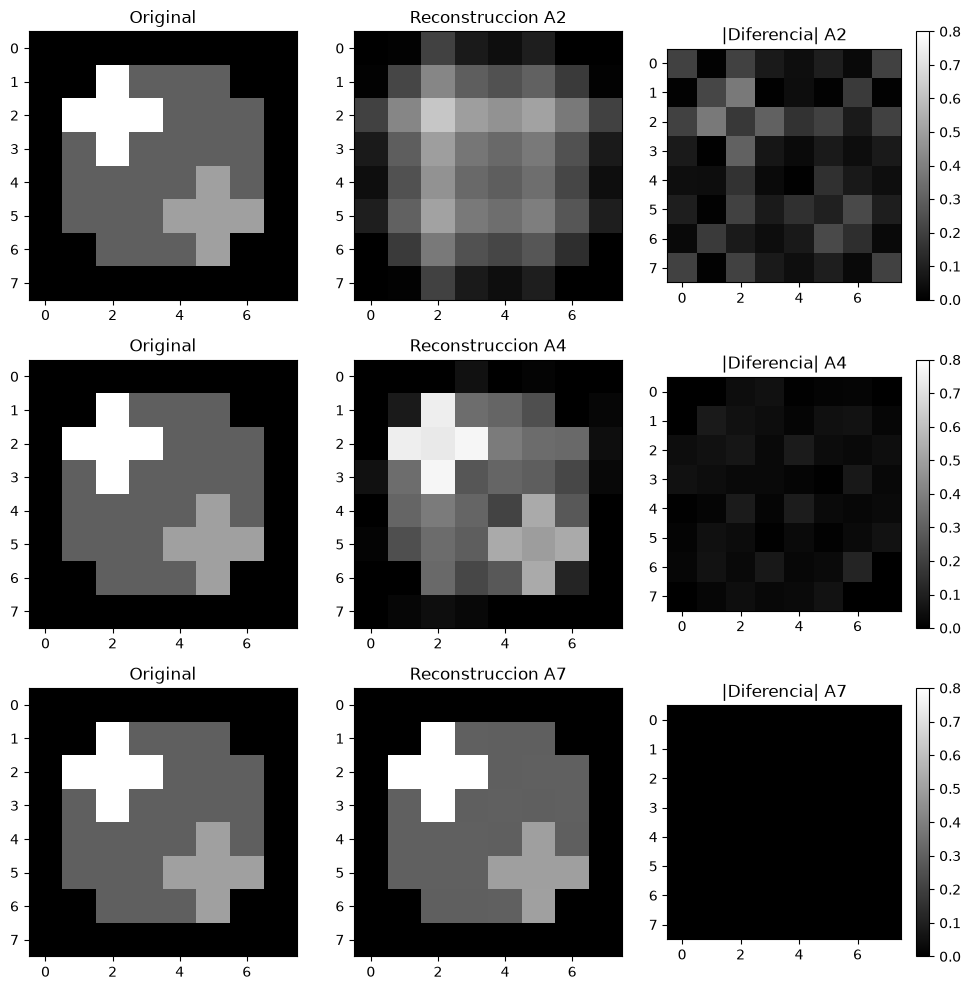

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

# k = 2
X_2_rec = x_raya_2.reshape(8,8)
dif_2 = np.abs(X_2_rec - X_fantoma)
axes[0,0].imshow(X_fantoma, cmap="gray", vmin=0, vmax=0.8)
axes[0,0].set_title(f"Original")
axes[0,1].imshow(X_2_rec, cmap="gray", vmin=0, vmax=0.8)
axes[0,1].set_title(f"Reconstruccion A2")
im = axes[0,2].imshow(dif_2, cmap="gray", vmin=0, vmax=0.8)
axes[0,2].set_title(f"|Diferencia| A2")

# k = 4
X_4_rec = x_raya_4.reshape(8,8)
dif_4 = np.abs(X_4_rec - X_fantoma)
axes[1,0].imshow(X_fantoma, cmap="gray", vmin=0, vmax=0.8)
axes[1,0].set_title(f"Original")
axes[1,1].imshow(X_4_rec, cmap="gray", vmin=0, vmax=0.8)
axes[1,1].set_title(f"Reconstruccion A4")
im = axes[1,2].imshow(dif_4, cmap="gray", vmin=0, vmax=0.8)
axes[1,2].set_title(f"|Diferencia| A4")

# k = 7
X_7_rec = x_raya_7.reshape(8,8)
dif_7 = np.abs(X_7_rec - X_fantoma)
axes[2,0].imshow(X_fantoma, cmap="gray", vmin=0, vmax=0.8)
axes[2,0].set_title(f"Original")
axes[2,1].imshow(X_7_rec, cmap="gray", vmin=0, vmax=0.8)
axes[2,1].set_title(f"Reconstruccion A7")
im = axes[2,2].imshow(dif_7, cmap="gray", vmin=0, vmax=0.8)
axes[2,2].set_title(f"|Diferencia| A7")

plt.tight_layout()
plt.show()

##### ¿Por qué un residuo cercano a cero no garantiza que la imagen original haya sido recuperada correctamente?
1. El residuo $r_k = b_k - A_k{\hat x}_k$ mide qué tanto coinciden los rayos simulados con los medidos. Si no hay ruido, el sistema será compatible, por lo que `lstsq` encuentra una imagen ${\hat x}$ que cumple $r_k {\approx}0$ 
2. Sin embargo, para $A_2$ y $A_4$, la matriz tiene espacio nulo no trivial $(dim(Nul(A_k))>0)$. Esto significa que cualquier imagen es $x_{fantoma}=x_{fila} + x_{nulo}$, con $x_{nulo} {\in} Nul(A_k)$
3. Como `lstsq` busca la sol de norma minima, descarta la componente $x_{nulo}$
4. Por lo tanto, ${\hat x}_k$ perdio toda la info que estaba en el espacio nulo. Por eso la imagen reconstruida con $A_2$ y $A_4$ se ve borrosa y su error relativo es != 0.
5. Solo en $A_7$, donde dim(Nul($A_7$)) = 0, la unica solucion compatible es la imagen real, logrando un error relativo igual a 0